In [29]:
import pandas as pd
import numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df = pd.read_csv("../dados/historico_barbearia.csv")

In [31]:
df.head()


,id_agendamento,id_cliente,nome_cliente,telefone,data_atendimento,barbeiro,servico,valor_pago
0,1,1,Cliente_001,98987423388,2025-11-26,Mateus,Corte,45.0
1,2,1,Cliente_001,98987423388,2025-12-15,Lucas,Corte + Barba,75.0
2,3,1,Cliente_001,98987423388,2026-01-01,Lucas,Corte,45.0
3,4,1,Cliente_001,98987423388,2026-01-16,Lucas,Corte,45.0
4,5,1,Cliente_001,98987423388,2026-01-29,Lucas,Corte,45.0


In [32]:
print(df.shape)

(5284, 8)


In [33]:
# 1. Garantir tipo datetime e ordenar por cliente e data
df['data_atendimento'] = pd.to_datetime(df['data_atendimento'])
df = df.sort_values(by=['id_cliente', 'data_atendimento']).reset_index(drop=True)

# 2. Visão Macro (Métricas de Negócio)
print("--- RESUMO GERAL DA BARBEARIA ---")
print(f"Total de Atendimentos: {len(df)}")
print(f"Total de Clientes Únicos: {df['id_cliente'].nunique()}")
print(f"Faturamento Total: R$ {df['valor_pago'].sum():,.2f}")
print(f"Ticket Médio Geral: R$ {df['valor_pago'].mean():.2f}")
print(f"Período: {df['data_atendimento'].min().date()} até {df['data_atendimento'].max().date()}\n")

print("--- DISTRIBUIÇÃO DE SERVIÇOS (%) ---")
print((df['servico'].value_counts(normalize=True) * 100).round(1))

--- RESUMO GERAL DA BARBEARIA ---
Total de Atendimentos: 5284
Total de Clientes Únicos: 300
Faturamento Total: R$ 279,220.00
Ticket Médio Geral: R$ 52.84
Período: 2025-11-01 até 2026-11-20

--- DISTRIBUIÇÃO DE SERVIÇOS (%) ---
servico
Corte            50.4
Corte + Barba    34.5
Barba            10.1
Sobrancelha       5.0
Name: proportion, dtype: float64


In [34]:
# Data de referência (último dia registrado na base)
data_referencia = df['data_atendimento'].max()

# Calcula a diferença em dias entre visitas consecutivas do mesmo cliente
df['intervalo_dias'] = df.groupby('id_cliente')['data_atendimento'].diff().dt.days

# Agrupa por cliente para criar a tabela de perfil (RFM + Ciclo descoberto)
df_clientes = df.groupby(['id_cliente', 'nome_cliente', 'telefone']).agg(
    ultimo_corte=('data_atendimento', 'max'),
    total_visitas=('id_agendamento', 'count'),
    frequencia_media_dias=('intervalo_dias', 'mean'),
    ticket_medio=('valor_pago', 'mean'),
    barbeiro_preferido=('barbeiro', lambda x: x.mode()[0]) # Barbeiro mais frequente
).reset_index()

# Calcula há quantos dias o cliente não aparece (Recência)
df_clientes['recencia_dias'] = (data_referencia - df_clientes['ultimo_corte']).dt.days

# Para clientes com apenas 1 visita (frequencia_media_dias = NaN), preenchemos com a mediana geral da barbearia
mediana_geral = df_clientes['frequencia_media_dias'].median()
df_clientes['frequencia_media_dias'] = df_clientes['frequencia_media_dias'].fillna(mediana_geral)

# Calcula a Razão de Atraso (> 1.0 significa que já passou do prazo habitual)
df_clientes['razao_atraso'] = (df_clientes['recencia_dias'] / df_clientes['frequencia_media_dias']).round(2)

print(f"Mediana de retorno da barbearia: {mediana_geral:.1f} dias")
df_clientes.head(10)

Mediana de retorno da barbearia: 20.5 dias


,id_cliente,nome_cliente,telefone,ultimo_corte,total_visitas,frequencia_media_dias,ticket_medio,barbeiro_preferido,recencia_dias,razao_atraso
0,1,Cliente_001,98987423388,2026-11-18,26,14.280000,51.538462,Lucas,2,0.14
1,2,Cliente_002,98981769598,2026-11-17,14,29.076923,42.142857,Lucas,3,0.10
2,3,Cliente_003,98988734102,2026-11-01,17,21.000000,53.823529,Lucas,19,0.90
3,4,Cliente_004,98988983441,2026-11-06,19,20.111111,52.368421,Rafael,14,0.70
4,5,Cliente_005,98986491590,2026-11-12,19,20.500000,51.315789,Lucas,8,0.39
5,6,Cliente_006,98984693305,2026-10-29,9,43.750000,50.555556,Lucas,22,0.50
6,7,Cliente_007,98985197571,2026-11-01,13,28.083333,58.076923,Mateus,19,0.68
7,8,Cliente_008,98981533636,2026-11-02,13,29.083333,50.384615,Lucas,18,0.62
8,9,Cliente_009,98985035493,2026-11-12,18,21.411765,44.444444,Mateus,8,0.37
9,10,Cliente_010,98989551881,2026-11-13,18,21.411765,60.555556,Lucas,7,0.33


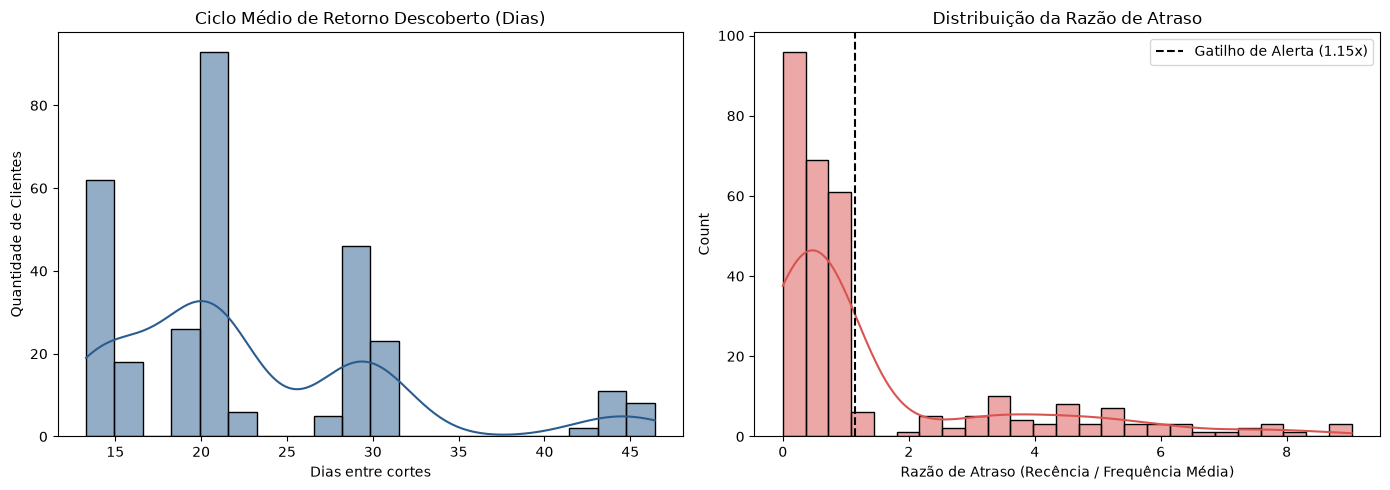

Clientes em alerta de abandono (atraso >= 15%): 71 de 300 clientes
Receita imediata em jogo: R$ 3,762.96


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Distribuição da Frequência Média Descoberta
sns.histplot(df_clientes['frequencia_media_dias'], bins=20, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title('Ciclo Médio de Retorno Descoberto (Dias)')
axes[0].set_xlabel('Dias entre cortes')
axes[0].set_ylabel('Quantidade de Clientes')

# Gráfico 2: Distribuição da Razão de Atraso
sns.histplot(df_clientes['razao_atraso'], bins=25, kde=True, ax=axes[1], color='#d9534f')
axes[1].axvline(1.15, color='black', linestyle='--', label='Gatilho de Alerta (1.15x)')
axes[1].set_title('Distribuição da Razão de Atraso')
axes[1].set_xlabel('Razão de Atraso (Recência / Frequência Média)')
axes[1].legend()

plt.tight_layout()
plt.show()

# Filtro de Oportunidade Comercial (Clientes em Risco)
em_risco = df_clientes[df_clientes['razao_atraso'] >= 1.15].sort_values(by='razao_atraso', ascending=False)
receita_risco = em_risco['ticket_medio'].sum()

print(f"Clientes em alerta de abandono (atraso >= 15%): {len(em_risco)} de {len(df_clientes)} clientes")
print(f"Receita imediata em jogo: R$ {receita_risco:,.2f}")